# Phase 6a: Machine learning models on the Phase 4 features

The question of this notebook: **do the satellite and weather features improve the yield prediction beyond the ground data, and which model family works best?**

Everything is tested with the Phase 5 rules: only the **1,019 development fields** are used, with the same folds (spatial groups of 1 km, 10 km blocks, leave one year out, leave one taluka out). The **183 hold-out fields stay locked** until Phase 8. The reference from Phase 5 is CatBoost on the 11 ground features: **r = 0.35 when a whole taluka is left out**. The target is Cao et al. (2026): r = 0.52 for a new region.

| Step | What |
|---|---|
| 1 | The five model families and their settings |
| 2 | Ground data + one feature group at a time: which groups help? |
| 3 | Ground + all helpful groups, and all features |
| 4 | Five model families on the chosen features, all five test schemes |
| 5 | Paired tests: is the improvement real or chance? |
| 6 | Scores per taluka, per year, at village level, and next to Cao et al. |
| 7 | Which features the model uses |
| 8 | Is the 1 km grouping still right for the new model's errors? |
| 9 | Figures and the error map |
| 10 | Save |

**No tuning here.** CatBoost keeps the Phase 5 settings; the other models use standard settings (Step 1). Tuning with an inner validation inside each training fold comes in Phase 6b, after this comparison. Deep learning models (Phase 6c) and the physics-guided model (Phase 7) will run on the IIT HPC.

## Step 0: Setup

Loads the Phase 4 clean feature table (331 features), the feature groups, the yields and the Phase 5 folds. Missing categories become their own class, as in Phase 5.

**Found:** 1,019 development fields and 331 features; the 183 hold-out fields are locked and not used. Run on the IIT Bombay Prajna cluster (a40 node, 32 CPU cores), 26 minutes in total.

In [1]:
from pathlib import Path
import sys, time, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from libpysal.weights import W
from esda.moran import Moran
from catboost import CatBoostRegressor
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
warnings.filterwarnings("ignore")

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
sys.path.insert(0, str(ROOT / "src"))
from evaluation import evaluate, compare, metrics, MeanBaseline
OUT = ROOT / "results" / "phase6"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures" / "phase6"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

f = gpd.read_file(ROOT / "data" / "processed_v2" / "yield_spatial_v2.gpkg").set_index("uid")
X = pd.read_csv(ROOT / "results" / "phase4" / "P4_features_clean.csv").set_index("uid")
dic = pd.read_csv(ROOT / "results" / "phase4" / "P4_feature_dictionary.csv").set_index("feature")
FOLDS = pd.read_csv(ROOT / "results" / "phase5" / "folds_v2.csv").set_index("uid")
dev = X.index[~X["holdout"]]                                     # 1,019 development fields; the 183 hold-out fields stay locked
Xd, yd = X.loc[dev].drop(columns="holdout"), f.loc[dev, "crop_yield"]
CAT = ["year", "ground_variety", "ground_irrigation", "ground_soil_color_group", "ground_soil_texture_group", "ground_soil_depth_group", "ground_soil_structure_group"]
for c in CAT:                                                    # missing categories become their own class (as in Phase 5)
    Xd[c] = Xd[c].astype(object).where(Xd[c].notna(), "missing").astype(str)
fold_cols = [c for c in FOLDS.columns if c.startswith(("random_s", "group_s", "block_s"))] + ["loyo", "loto"]
F_ALL = FOLDS.loc[dev, fold_cols]                                # 85 test folds: random, group and block 5 x 5, 4 years, 6 talukas
F_FAST = FOLDS.loc[dev, ["group_s1", "group_s2", "group_s3", "loto"]]   # for the many group tests: 15 + 6 test folds
grp = dic["group"].reindex(Xd.columns)
print(f"development fields: {len(dev)} | features: {Xd.shape[1]} | hold-out fields locked: {int(X['holdout'].sum())}")
print("features per group:", grp.value_counts().to_dict())

development fields: 1019 | features: 331 | hold-out fields locked: 183
features per group: {'s2_month_spread': 77, 's1_month_spread': 53, 'weather_month': 31, 's2_month_mean': 21, 'weather_stage': 21, 's1_month_mean': 18, 'modis': 18, 's1_season': 15, 's2_quality': 14, 'ground': 11, 'glcm_s1': 9, 's2_season': 9, 'rain_month': 7, 's1_quality': 6, 'era5_rain': 5, 'terrain': 5, 'glcm_s2': 4, 'soil': 4, 'neighbourhood': 3}


## Step 1: The models

| Model | What it does | Settings |
|---|---|---|
| Overall mean | predicts the training mean (floor) | none |
| Ridge regression | a straight-line model on all features, with a penalty that keeps the weights small | penalty chosen inside each training set from 30 values (RidgeCV) |
| Random forest | average of 500 decision trees, each on a random part of the data | 500 trees, at least 5 fields per leaf, a third of the features per split |
| SVR (RBF) | support vector regression, a smooth curved model | C = 1, epsilon = 0.1, gamma "scale"; yield scaled |
| CatBoost | gradient boosted trees that handle categories and missing values by themselves | Phase 5 settings: 500 trees, depth 6, learning rate 0.05 |

Ridge, random forest and SVR need numbers only, so categories become 0/1 columns (rare ones grouped), missing values get the median plus a "was missing" flag, and all columns are scaled. All of this is learned on the training folds only.

**Found:** five model families ready: overall mean, ridge regression, random forest, SVR (RBF) and CatBoost (Phase 5 settings). No tuning.

In [2]:
# Step 1: the models. CatBoost keeps the Phase 5 settings (no tuning yet). The other families get standard settings.
def make_catboost(cols):
    cats = [c for c in CAT if c in cols]
    return lambda: CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05, loss_function="RMSE", random_seed=SEED, verbose=0,
                                     cat_features=cats, allow_writing_files=False, thread_count=int(__import__('os').environ.get('SLURM_CPUS_PER_TASK', -1)))
def prep(cols):
    """for models that need numbers only: one-hot for categories; median for missing values plus a 'was missing' flag; scaled"""
    cats = [c for c in CAT if c in cols]; nums = [c for c in cols if c not in cats]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), cats),
                              ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), nums)])
MODELS = {
    "Overall mean": lambda cols: (lambda: MeanBaseline()),
    "Ridge regression": lambda cols: (lambda: make_pipeline(prep(cols), RidgeCV(alphas=np.logspace(-1, 4, 30)))),
    "Random forest": lambda cols: (lambda: make_pipeline(prep(cols), RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED))),
    "SVR (RBF)": lambda cols: (lambda: TransformedTargetRegressor(make_pipeline(prep(cols), SVR(kernel="rbf", C=1.0, epsilon=0.1, gamma="scale")), transformer=StandardScaler())),
    "CatBoost": make_catboost,
}
def run(name, cols, folds, model="CatBoost"):
    t = time.time(); pf, sm, oof = evaluate(MODELS[model](cols), Xd[cols], yd, folds)
    for d in (pf, sm, oof): d["config"] = name; d["model"] = model
    sm["features"] = len(cols)
    print(f"  {model:17s} | {name:32s} | {len(cols):3d} features | {time.time() - t:5.0f} s | " +
          " | ".join(f"{s} r = {v:.3f}" for s, v in zip(sm["scheme"], sm["r_mean"])))
    return pf, sm, oof
print("models:", list(MODELS))

models: ['Overall mean', 'Ridge regression', 'Random forest', 'SVR (RBF)', 'CatBoost']


## Step 2: Which feature groups help?

CatBoost is trained on the ground data alone, then on the ground data **plus one group at a time** (10 groups). Each run uses the same 21 test folds: spatial groups (3 repeats × 5 folds) and leave one taluka out (6 folds).

- **loto r change** is the main number: how much the group raises r when a whole taluka is new. As agreed, a group counts as helpful if it raises this r.
- **RMSE gain (group CV)** with the Wilcoxon and corrected t-test p-values says whether the group lowers the error on new fields more than chance would.

Why both: a feature can help on new fields near known ones (spatial groups) but not in a new taluka, if it only marks **where** a field is. Coarse weather (one 10 km pixel for many fields) is the main suspect.

**Found:** (r = mean over test folds; ground only: 1 km groups 0.350, new taluka 0.351)

| Added group | r, 1 km groups | r, new taluka | change, new taluka | Wilcoxon p (RMSE) | corrected t p |
|---|---|---|---|---|---|
| Sentinel-2 (monthly, season) | 0.473 | 0.410 | +0.060 | 0.0001 | 0.056 |
| Weather by month | 0.525 | 0.384 | +0.034 | 0.0002 | 0.096 |
| Weather in crop stages | 0.409 | 0.369 | +0.019 | 0.107 | 0.303 |
| Texture and neighbourhood | 0.351 | 0.356 | +0.005 | 0.277 | 0.522 |
| Sentinel-2 spread | 0.344 | 0.324 | −0.026 | 0.847 | 0.817 |
| Rain by month (CHIRPS) | 0.393 | 0.317 | −0.034 | 0.359 | 0.756 |
| Sentinel-1 (monthly, season) | 0.348 | 0.304 | −0.047 | 0.679 | 0.604 |
| MODIS | 0.310 | 0.301 | −0.049 | 0.561 | 0.770 |
| Terrain and soil | 0.336 | 0.293 | −0.057 | 0.804 | 0.779 |
| Sentinel-1 spread | 0.315 | 0.278 | −0.072 | 0.489 | 0.928 |

- Sentinel-2 is the clearest gain: higher r in both tests, and the lower error is unlikely to be chance.
- Monthly weather gives the biggest gain with 1 km groups (0.35 to 0.52) but a small one for a new taluka (+0.03): one ERA5 pixel covers about 6 fields, so it partly marks where a field is.
- Sentinel-1 does not help on its own; it lowers r a little, as the weak links in Phase 4 suggested.
- Helpful groups (raise the new-taluka r): Sentinel-2, monthly weather, crop-stage weather, texture and neighbourhood.

In [3]:
# Step 2: does each group help? Ground data alone, then ground + one group at a time (CatBoost, same folds)
BLOCKS = {"Sentinel-2 (monthly, season)": ["s2_month_mean", "s2_season", "s2_quality"], "Sentinel-2 spread": ["s2_month_spread"],
          "Sentinel-1 (monthly, season)": ["s1_month_mean", "s1_season", "s1_quality"], "Sentinel-1 spread": ["s1_month_spread"],
          "Texture and neighbourhood": ["glcm_s1", "glcm_s2", "neighbourhood"], "Weather in crop stages": ["weather_stage"],
          "Weather by month": ["weather_month", "era5_rain"], "Rain by month (CHIRPS)": ["rain_month"],
          "Terrain and soil": ["terrain", "soil"], "MODIS": ["modis"]}
GROUND = list(grp[grp == "ground"].index)
cols_of = lambda groups: [c for c in Xd.columns if grp[c] in groups]
res = {"Ground only": run("Ground only", GROUND, F_FAST)}
for b, gs in BLOCKS.items():
    res[b] = run("+ " + b, GROUND + cols_of(gs), F_FAST)
rows = []
base = res["Ground only"]
for b, (pf, sm, _) in res.items():
    s = sm.set_index("scheme")
    row = {"added group": b, "features": int(s["features"].iloc[0]), "group r": s.at["group", "r_mean"], "group RMSE": s.at["group", "RMSE_q_acre_mean"],
           "loto r": s.at["loto", "r_mean"], "loto RMSE": s.at["loto", "RMSE_q_acre_mean"]}
    if b != "Ground only":
        c = compare(base[0], pf, "RMSE_q_acre", "group")                     # A = ground only, B = with the group
        row["RMSE gain (group CV)"] = c["mean_diff_A_minus_B"]; row["Wilcoxon p"] = c["wilcoxon_p"]; row["corrected t p"] = c["corrected_t_p"]
    rows.append(row)
abl = pd.DataFrame(rows); abl["loto r change"] = abl["loto r"] - abl.at[0, "loto r"]
abl.to_csv(OUT / "P6_group_tests.csv", index=False)
print(abl.round(3).to_string(index=False))
KEEP = [b for b in BLOCKS if abl.set_index("added group").at[b, "loto r change"] > 0]
print("\ngroups that raise leave-one-taluka-out r on their own:", KEEP)

  CatBoost          | Ground only                      |  11 features |    62 s | group r = 0.350 | loto r = 0.351


  CatBoost          | + Sentinel-2 (monthly, season)   |  55 features |    73 s | group r = 0.473 | loto r = 0.410


  CatBoost          | + Sentinel-2 spread              |  88 features |    52 s | group r = 0.344 | loto r = 0.324


  CatBoost          | + Sentinel-1 (monthly, season)   |  50 features |    73 s | group r = 0.348 | loto r = 0.304


  CatBoost          | + Sentinel-1 spread              |  64 features |    56 s | group r = 0.315 | loto r = 0.278


...

  CatBoost          | + Weather by month               |  47 features |    78 s | group r = 0.525 | loto r = 0.384


  CatBoost          | + Rain by month (CHIRPS)         |  18 features |    64 s | group r = 0.393 | loto r = 0.317


  CatBoost          | + Terrain and soil               |  20 features |    68 s | group r = 0.336 | loto r = 0.293


  CatBoost          | + MODIS                          |  29 features |    73 s | group r = 0.310 | loto r = 0.301


                 added group  features  group r  group RMSE  loto r  loto RMSE  RMSE gain (group CV)  Wilcoxon p  corrected t p  loto r change
                 Ground only        11    0.350       2.975   0.351      2.815                   NaN         NaN            NaN          0.000
Sentinel-2 (monthly, season)        55    0.473       2.682   0.410      2.678                 0.293       0.000          0.056          0.060
           Sentinel-2 spread        88    0.344       2.952   0.324      2.819                 0.023       0.847          0.817         -0.026
Sentinel-1 (monthly, season)        50    0.348       2.931   0.304      2.813                 0.043       0.679          0.604         -0.047
           Sentinel-1 spread        64    0.315       2.967   0.278      2.824                 0.007       0.489          0.928         -0.072
   Texture and neighbourhood        27    0.351       2.936   0.356      2.777                 0.038       0.277          0.522          0.005

## Step 3: Putting the groups together

Two combinations: the ground data plus **every group that helped on its own** in Step 2, and **all 331 features**. The one with the higher leave-one-taluka-out r is used from here on.

**Found:** ground + the 4 helpful groups (128 features): r = 0.520 with 1 km groups and **0.397 for a new taluka** (RMSE 2.66 q/acre). All 331 features: 0.480 and 0.337, worse than ground only for a new taluka; adding every feature adds noise. Chosen: **ground + helpful groups (128 features)**.

In [4]:
# Step 3: combine. (a) ground + every group that helped on its own, (b) ground + all groups
SETS = {"Ground only": GROUND, "Ground + helpful groups": GROUND + cols_of(sum((BLOCKS[b] for b in KEEP), [])), "All features": list(Xd.columns)}
comb = {k: (res["Ground only"] if k == "Ground only" else run(k, v, F_FAST)) for k, v in SETS.items()}
cmb = pd.concat([sm for _, sm, _ in comb.values()])[["config", "features", "scheme", "r_mean", "r_sd", "RMSE_q_acre_mean", "R2_mean"]]
cmb.to_csv(OUT / "P6_feature_sets.csv", index=False)
print(cmb.round(3).to_string(index=False))
lr = cmb[cmb["scheme"] == "loto"].set_index("config")["r_mean"]
BEST = lr.drop("Ground only").idxmax()
print(f"\nfeature set used from here on: {BEST} ({len(SETS[BEST])} features)")

  CatBoost          | Ground + helpful groups          | 128 features |    65 s | group r = 0.520 | loto r = 0.397


  CatBoost          | All features                     | 331 features |    83 s | group r = 0.480 | loto r = 0.337
                 config  features scheme  r_mean  r_sd  RMSE_q_acre_mean  R2_mean
            Ground only        11  group   0.350 0.085             2.975    0.048
            Ground only        11   loto   0.351 0.111             2.815   -0.011
Ground + helpful groups       128  group   0.520 0.160             2.543    0.268
Ground + helpful groups       128   loto   0.397 0.091             2.659    0.115
           All features       331  group   0.480 0.152             2.662    0.214
           All features       331   loto   0.337 0.089             2.740    0.067

feature set used from here on: Ground + helpful groups (128 features)


## Step 4: Five model families

All five families on the chosen feature set, and CatBoost on the ground data as the reference, each tested on all **85 test folds** (random, spatial groups and 10 km blocks 5 × 5 each, 4 years, 6 talukas). r and RMSE are means over the test folds, as in Cao et al.

**Found:** (Pearson r, mean over test folds)

| Model | Random | 1 km groups | 10 km blocks | New year | New taluka |
|---|---|---|---|---|---|
| Random forest | 0.591 | 0.497 | 0.402 | 0.118 | **0.399** |
| CatBoost | 0.581 | 0.519 | 0.394 | 0.154 | 0.397 |
| Ridge regression | 0.494 | 0.431 | 0.390 | 0.236 | 0.366 |
| SVR (RBF) | 0.505 | 0.429 | 0.406 | 0.024 | 0.358 |
| CatBoost, ground only | 0.393 | 0.355 | 0.371 | 0.098 | 0.351 |

- RMSE for a new taluka: random forest 2.67, CatBoost 2.66, ground only 2.81, overall mean 2.89 q/acre.
- The tree models (random forest, CatBoost) are best. All models fail for a new year (r 0.02 to 0.24): 4 seasons are too few to learn how a new season behaves.
- The 1 km group score (about 0.50) is clearly higher than the 10 km block and new-taluka scores (about 0.40); see Step 8.

In [5]:
# Step 4: five model families on the chosen feature set, all five test schemes (85 test folds each)
cols = SETS[BEST]
fam = {}
for m in MODELS:
    fam[m] = run(BEST, cols, F_ALL, model=m)
fam["CatBoost, ground only"] = run("Ground only", GROUND, F_ALL, model="CatBoost")
SUM = pd.concat([sm.assign(model=k) for k, (_, sm, _) in fam.items()])
SUM.to_csv(OUT / "P6_model_scores.csv", index=False)
pd.concat([pf.assign(model=k) for k, (pf, _, _) in fam.items()]).to_csv(OUT / "P6_model_scores_per_fold.csv", index=False)
show = SUM.pivot_table(index="model", columns="scheme", values="r_mean").reindex(columns=["random", "group", "block", "loyo", "loto"])
print("\nPearson r, mean over test folds:"); print(show.round(3).to_string())
print("\nRMSE (q/acre), mean over test folds:"); print(SUM.pivot_table(index="model", columns="scheme", values="RMSE_q_acre_mean").reindex(columns=show.columns).round(2).to_string())

  Overall mean      | Ground + helpful groups          | 128 features |     0 s | random r = nan | group r = nan | block r = nan | loyo r = nan | loto r = nan


  Ridge regression  | Ground + helpful groups          | 128 features |    11 s | random r = 0.494 | group r = 0.431 | block r = 0.390 | loyo r = 0.236 | loto r = 0.366


  Random forest     | Ground + helpful groups          | 128 features |    56 s | random r = 0.591 | group r = 0.497 | block r = 0.402 | loyo r = 0.118 | loto r = 0.399


  SVR (RBF)         | Ground + helpful groups          | 128 features |     8 s | random r = 0.505 | group r = 0.429 | block r = 0.406 | loyo r = 0.024 | loto r = 0.358


  CatBoost          | Ground + helpful groups          | 128 features |   245 s | random r = 0.581 | group r = 0.519 | block r = 0.394 | loyo r = 0.154 | loto r = 0.397


  CatBoost          | Ground only                      |  11 features |   262 s | random r = 0.393 | group r = 0.355 | block r = 0.371 | loyo r = 0.098 | loto r = 0.351



Pearson r, mean over test folds:
scheme                 random  group  block   loyo   loto
model                                                    
CatBoost                0.581  0.519  0.394  0.154  0.397
CatBoost, ground only   0.393  0.355  0.371  0.098  0.351
Random forest           0.591  0.497  0.402  0.118  0.399
Ridge regression        0.494  0.431  0.390  0.236  0.366
SVR (RBF)               0.505  0.429  0.406  0.024  0.358

RMSE (q/acre), mean over test folds:
scheme                 random  group  block  loyo  loto
model                                                  
CatBoost                 2.54   2.55   2.82  3.48  2.66
CatBoost, ground only    2.91   2.96   2.88  3.88  2.81
Overall mean             3.14   3.10   3.05  3.35  2.89
Random forest            2.54   2.66   2.82  3.87  2.67
Ridge regression         2.75   2.82   2.88  3.95  2.79
SVR (RBF)                2.72   2.79   2.78  3.30  2.71


## Step 5: Real improvement or chance?

Each model is compared with the reference (CatBoost on ground data) **fold by fold** on the same test folds: the Wilcoxon signed-rank test and the corrected resampled t-test (Nadeau and Bengio 2003), which allows for the overlap between training sets. With only 6 talukas, the leave-one-taluka-out tests have little power; the 25 spatial group folds are the stronger test.

**Found:** best model for a new taluka: **random forest**. Compared with CatBoost on ground data only:
- 1 km groups (25 folds): RMSE 0.30 q/acre lower (Wilcoxon p < 0.001, corrected t-test p = 0.023); r 0.14 higher (p < 0.001 and p = 0.048).
- New taluka (6 folds): r 0.05 higher (Wilcoxon p = 0.031, corrected t-test p = 0.015); RMSE 0.15 lower but not significant (p = 0.43).
- CatBoost with the same features: similar gains but borderline (corrected t-test p = 0.052 for RMSE with 1 km groups; not significant for a new taluka).
- Ridge and SVR: lower error with 1 km groups only by the Wilcoxon test, not by the stricter corrected t-test.

In [6]:
# Step 5: is a model really better than the ground-only reference? Paired tests on the same folds
REF = fam["CatBoost, ground only"][0]
rows = []
for m in ["Ridge regression", "Random forest", "SVR (RBF)", "CatBoost"]:
    for scheme in ["group", "loto"]:
        for metric in ["RMSE_q_acre", "r"]:
            c = compare(REF, fam[m][0], metric, scheme); c["model"] = m; rows.append(c)
tests = pd.DataFrame(rows)[["model", "scheme", "metric", "folds", "mean_diff_A_minus_B", "wilcoxon_p", "corrected_t_p"]]
tests = tests.rename(columns={"mean_diff_A_minus_B": "reference minus model"})
tests.to_csv(OUT / "P6_paired_tests.csv", index=False)
best_model = SUM[SUM["scheme"] == "loto"].set_index("model").drop(["Overall mean", "CatBoost, ground only"])["r_mean"].idxmax()
print(f"best model on leave-one-taluka-out r: {best_model}")
print("A = CatBoost on ground data only; B = each model with the chosen features.")
print("RMSE: positive = the model has a smaller error. r: negative = the model has a higher r.")
print(tests.round(3).to_string(index=False))

best model on leave-one-taluka-out r: Random forest
A = CatBoost on ground data only; B = each model with the chosen features.
RMSE: positive = the model has a smaller error. r: negative = the model has a higher r.
           model scheme      metric  folds  reference minus model  wilcoxon_p  corrected_t_p
Ridge regression  group RMSE_q_acre     25                  0.138       0.007          0.201
Ridge regression  group           r     25                 -0.076       0.002          0.194
Ridge regression   loto RMSE_q_acre      6                  0.026       1.000          0.911
Ridge regression   loto           r      6                 -0.015       1.000          0.786
   Random forest  group RMSE_q_acre     25                  0.299       0.000          0.023
   Random forest  group           r     25                 -0.142       0.000          0.048
   Random forest   loto RMSE_q_acre      6                  0.149       0.219          0.432
   Random forest   loto           r      

## Step 6: Per taluka, per year, village level, and Cao et al.

All numbers use the **leave-one-taluka-out** predictions of the best model: every field is predicted by a model that never saw its taluka.

- **Per taluka** and **per year:** where and when the model works.
- **Village level:** the mean observed and mean predicted yield of every village with 3 or more fields in a year. Averages remove part of the field noise, so this is closer to Cao et al.'s county scale.
- **Cao et al.:** the same three kinds of test (random, new region, new season).

**Found:** (random forest, leave-one-taluka-out predictions)
- Per taluka: r from 0.24 (Renapur) to 0.52 (Shirur-Anantpal); Nilanga 0.50, Chakur 0.41, Latur 0.39, Ausa 0.33. Ausa has the largest error (RMSE 4.4 q/acre).
- Per year: 2022 −0.31 (45 fields), 2023 0.13 (52), 2024 0.24 (262), 2025 0.22 (658). Inside one year the model ranks fields only weakly; much of the overall r comes from telling good years from bad years.
- Village level (76 village-years with 3 or more fields): **r = 0.54**, R² = 0.29, RMSE 2.33 q/acre. Field level, same predictions pooled: r = 0.35.
- Compared with Cao et al. (2026): random 0.59 (theirs 0.90), new region **0.40** (theirs 0.52), new season 0.12 (theirs 0.86). Their test uses county averages over 20 years; ours uses single fields over 4 years. The village-level r (0.54) is closer to their scale but not the same.

In [7]:
# Step 6: how good is the best model in each year, each taluka, and at village level?
pf_b, sm_b, oof_b = fam[best_model]
lo = oof_b[oof_b["scheme"] == "loto"].merge(f[["year", "taluka", "village"]], left_on="uid", right_index=True)
print("leave-one-taluka-out, per taluka (the taluka is never seen in training):")
print(pf_b[pf_b["scheme"] == "loto"][["fold", "n", "r", "R2", "RMSE_q_acre", "bias_q_acre"]].round(3).to_string(index=False))
print("\nsame predictions, split by year:")
print(pd.DataFrame({yr: metrics(g["y"], g["pred"]) for yr, g in lo.groupby("year")}).T[["n", "r", "R2", "RMSE_q_acre"]].round(3).to_string())
# village level: mean of observed and of predicted yield per village and year (villages with 3 or more fields)
vil = lo.groupby(["year", "village"]).agg(n=("y", "size"), y=("y", "mean"), pred=("pred", "mean")).reset_index()
vil = vil[vil["n"] >= 3]
vm = metrics(vil["y"], vil["pred"])
print(f"\nvillage level (leave-one-taluka-out): {len(vil)} village-years with 3 or more fields | r = {vm['r']:.3f} | R2 = {vm['R2']:.3f} | RMSE = {vm['RMSE_q_acre']:.2f} q/acre")
fm = metrics(lo["y"], lo["pred"])
print(f"field level, same predictions pooled: r = {fm['r']:.3f}")
s = SUM[SUM["model"] == best_model].set_index("scheme")
cao = pd.DataFrame({"test": ["random", "new region", "new season"], "Cao et al. (2026) r": [0.90, 0.52, 0.86],
                    "our split": ["random 5-fold", "leave one taluka out", "leave one year out"],
                    "ours r (mean over folds)": [s.at["random", "r_mean"], s.at["loto", "r_mean"], s.at["loyo", "r_mean"]],
                    "ground only r": [SUM[(SUM.model == "CatBoost, ground only") & (SUM.scheme == k)]["r_mean"].iloc[0] for k in ["random", "loto", "loyo"]]})
cao.to_csv(OUT / "P6_vs_cao.csv", index=False)
print("\ncompared with Cao et al. (2026):"); print(cao.round(3).to_string(index=False))
vil.to_csv(OUT / "P6_village_level.csv", index=False)

leave-one-taluka-out, per taluka (the taluka is never seen in training):
           fold   n     r    R2  RMSE_q_acre  bias_q_acre
           Ausa 247 0.332 0.094        4.425        0.583
         Chakur  96 0.407 0.137        1.952        0.337
          Latur 325 0.391 0.106        2.417       -0.540
        Nilanga 162 0.503 0.198        2.294        0.107
        Renapur 107 0.241 0.005        2.426        0.526
Shirur-Anantpal  80 0.522 0.204        2.483       -0.042

same predictions, split by year:
          n      r     R2  RMSE_q_acre
2022   45.0 -0.314 -0.397        3.419
2023   52.0  0.134 -0.008        2.653
2024  262.0  0.238  0.051        4.221
2025  658.0  0.216  0.045        2.311

village level (leave-one-taluka-out): 76 village-years with 3 or more fields | r = 0.541 | R2 = 0.289 | RMSE = 2.33 q/acre
field level, same predictions pooled: r = 0.353

compared with Cao et al. (2026):
      test  Cao et al. (2026) r            our split  ours r (mean over folds)  ground

## Step 7: Which features does the model use?

CatBoost is trained once on all development fields with the chosen features, and its built-in importance (PredictionValuesChange: how much the predictions change when a feature is used) is summed per group. Importance shows what the model **uses**, not what **causes** yield.

**Found:** importance by group (CatBoost): monthly weather 21%, Sentinel-2 monthly means 19%, Sentinel-2 clear-look counts 12%, crop-stage weather 12%, ground 10%, Sentinel-1 texture 9%, Sentinel-2 season 6%, neighbourhood 4%, NDVI texture 4%, ERA5 rain 2%. Top features: October VPD (7.7%), November clear looks (5.9%), October soil moisture (3.1%), October clear looks (2.6%), crop duration (2.5%), October LSWI (2.4%), field area (2.4%). Coarse weather and cloud counts describe where and in which year a field is more than its crop, so part of the gain may come from place and time markers; Phase 6b tests the model without them.

In [8]:
# Step 7: which features does CatBoost use? (CatBoost trained once on all development fields, chosen feature set)
cb = MODELS["CatBoost"](cols)().fit(Xd[cols], yd)
imp = pd.DataFrame({"feature": cols, "importance": cb.get_feature_importance()}).assign(group=lambda d: grp.reindex(d["feature"]).values)
imp = imp.sort_values("importance", ascending=False); imp.to_csv(OUT / "P6_importance.csv", index=False)
gimp = imp.groupby("group")["importance"].agg(["sum", "size"]).sort_values("sum", ascending=False).rename(columns={"sum": "importance_%", "size": "features"})
print("importance by group (CatBoost PredictionValuesChange, sums to 100):"); print(gimp.round(1).to_string())
print("\ntop 15 features:"); print(imp.head(15).round(2).to_string(index=False))

importance by group (CatBoost PredictionValuesChange, sums to 100):
               importance_%  features
group                                
weather_month          21.1        31
s2_month_mean          19.2        21
s2_quality             12.4        14
weather_stage          12.2        21
ground                 10.1        11
glcm_s1                 9.0         9
s2_season               6.2         9
neighbourhood           4.2         3
glcm_s2                 3.8         4
era5_rain               1.7         5

top 15 features:
             feature  importance         group
         era5_VPD_10        7.74 weather_month
        s2_nclear_11        5.93    s2_quality
          era5_SM_10        3.08 weather_month
        s2_nclear_10        2.57    s2_quality
ground_crop_duration        2.54        ground
     s2_LSWI_10_mean        2.44 s2_month_mean
   ground_area_acres        2.40        ground
      nbr_VH_08_diff        2.27 neighbourhood
     s2_NDVI_08_mean        2.08 s2

## Step 8: Is 1 km still the right grouping distance?

Phase 5 chose 1 km because the errors of the ground-data model stayed alike up to 1 km. The slides promised to repeat this with the satellite model. Here: Moran's I of the new model's errors (spatial group test, repeat 1) in distance rings, next to the Phase 5 values. If the errors are now alike over longer distances, the spatial group test is too easy and the leave-one-taluka-out test matters even more.

**Found:** with the satellite model, the errors stay alike over longer distances than in Phase 5. In 2024, Moran's I is significant at 1 to 1.5 km (0.26), 1.5 to 2 km (0.14) and 2 to 3 km (0.14); in Phase 5 it stopped at 1 km. In 2025 it reaches about 2 km (0.09 and 0.06). So the 1 km grouping is now too small: the 1 km group score (about 0.50) is optimistic, and the 10 km block and new-taluka scores (about 0.40) are the honest ones. A grouping distance of about 3 km should be used from Phase 6b on.

In [9]:
# Step 8: is 1 km still the right grouping distance? Moran's I of the new model's errors (as Phase 5 did for the ground model)
pts = f.geometry.representative_point(); f["x"], f["y_m"] = pts.x, pts.y
gs1 = oof_b[(oof_b["scheme"] == "group") & (oof_b["repeat"] == "group_s1")].set_index("uid")
E = f.loc[gs1.index, ["year", "x", "y_m"]].assign(resid=gs1["y"] - gs1["pred"])
BINS = [(0, 250), (250, 500), (500, 1000), (1000, 1500), (1500, 2000), (2000, 3000), (3000, 5000)]
def ring_moran(g, lo_, hi):
    xy, r = g[["x", "y_m"]].to_numpy(), g["resid"].to_numpy(); t = cKDTree(xy)
    o, i = t.query_ball_point(xy, hi), t.query_ball_point(xy, lo_)
    nb = {k: sorted(set(o[k]) - set(i[k]) - {k}) for k in range(len(xy))}; keep = [k for k in nb if nb[k]]
    pos = {k: n for n, k in enumerate(keep)}
    w = W({pos[k]: [pos[j] for j in nb[k] if j in pos] for k in keep}, silence_warnings=True)
    if w.s0 / 2 < 30: return np.nan, np.nan
    w.transform = "r"; np.random.seed(SEED); mi = Moran(r[keep], w, permutations=999)
    return mi.I, mi.p_sim
rows = [{"year": yr, "from_m": a, "to_m": b, **dict(zip(["moran_I", "p"], ring_moran(E[E["year"] == yr], a, b)))} for yr in [2024, 2025] for a, b in BINS]
rc = pd.DataFrame(rows); rc.to_csv(OUT / "P6_error_correlogram.csv", index=False)
p5 = pd.read_csv(ROOT / "results" / "phase5" / "P5_error_correlogram.csv") if (ROOT / "results" / "phase5" / "P5_error_correlogram.csv").exists() else None
tab = rc.assign(I=lambda t: t["moran_I"].round(2).astype(str) + np.where(t["p"] < 0.05, " *", "")).pivot(index=["from_m", "to_m"], columns="year", values="I")
if p5 is not None:
    tab = tab.join(p5.assign(I=lambda t: t["moran_I"].round(2).astype(str) + np.where(t["p"] < 0.05, " *", "")).pivot(index=["from_m", "to_m"], columns="year", values="I").add_prefix("Phase 5 "))
print(f"Moran's I of the errors of {best_model} (spatial group CV, repeat 1); * = p < 0.05 (999 shuffles)")
print(tab.to_string())

Moran's I of the errors of Random forest (spatial group CV, repeat 1); * = p < 0.05 (999 shuffles)
year           2024     2025 Phase 5 2024 Phase 5 2025
from_m to_m                                           
0      250   0.49 *   0.27 *       0.46 *       0.16 *
250    500   0.33 *     0.02       0.35 *         0.01
500    1000  0.45 *    -0.01       0.46 *      -0.06 *
1000   1500  0.26 *   0.09 *        -0.01       0.08 *
1500   2000  0.14 *   0.06 *        -0.04         0.03
2000   3000  0.14 *     0.02       0.08 *         0.02
3000   5000    0.02  -0.04 *       0.08 *        -0.02


## Step 9: Figures

(a) the group tests, (b) the model families, (c) observed against predicted yield for fields and villages, (d) importance by group, (e) a map of the prediction errors in 2024 and 2025 (leave one taluka out). Saved in `reports/figures/phase6/`.

**Found:** five figures saved in `reports/figures/phase6/`.
- Observed against predicted: predictions stay between about 7 and 12 q/acre while observed yields range from about 1 to 47; the model pulls towards the average and misses very low and very high fields. The 2024 predictions sit higher than the 2025 ones, so much of the skill is telling good years from bad years. The few reported yields of 30 to 47 q/acre lie far above all predictions and inflate the RMSE.
- Village level: the points follow the 1:1 line better (r = 0.54), except one village with a very high reported mean.
- Error map: in 2024 whole clusters share one error sign (west Latur cluster too high, north-west cluster and Killari too low), matching the spatial pattern found in Step 8; in 2025 the errors are more mixed. Such patchy errors are what regression kriging (Phase 7) is meant to correct.
- Model families: the error bars overlap widely; the clear difference is satellite features against ground only, not between the tree models.

In [10]:
# Step 9: figures
LAB = {"random": "Random", "group": "Spatial groups", "block": "10 km blocks", "loyo": "New year", "loto": "New taluka"}
# (a) group tests
fig, ax = plt.subplots(figsize=(10, 4.8))
a2 = abl.iloc[1:].sort_values("loto r change")
ax.barh(a2["added group"], a2["loto r change"], color=np.where(a2["loto r change"] > 0, "#2E7D32", "#B0B0B0"))
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel(f"change in leave-one-taluka-out r compared with ground only (r = {abl.at[0, 'loto r']:.3f})")
ax.set_title("Ground data + one group at a time (CatBoost)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P6_group_tests.png", dpi=250, facecolor="white"); plt.show()
# (b) model families
order = ["Overall mean", "CatBoost, ground only", "Ridge regression", "Random forest", "SVR (RBF)", "CatBoost"]
sch = ["random", "group", "block", "loyo", "loto"]
fig, ax = plt.subplots(figsize=(11, 4.8)); wdt = 0.8 / len(order)
for i, m in enumerate(order):
    s = SUM[SUM["model"] == m].set_index("scheme").reindex(sch)
    ax.bar(np.arange(len(sch)) + (i - len(order) / 2 + 0.5) * wdt, s["r_mean"].fillna(0), wdt, yerr=s["r_sd"].fillna(0), capsize=2, label=m)
ax.set_xticks(range(len(sch)), [LAB[s] for s in sch]); ax.set_ylabel("Pearson r (mean over test folds)")
ax.axhline(0.52, color="#C62828", ls="--", lw=1); ax.text(4.45, 0.535, "Cao et al. new region 0.52", color="#C62828", ha="right", fontsize=9)
ax.set_ylim(min(0, np.nanmin(SUM["r_mean"]) - 0.05), 0.8); ax.legend(ncol=3, fontsize=9, loc="upper left", frameon=False)
ax.set_title(f"Model families, feature set: {BEST} (error bars = SD over folds)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P6_model_families.png", dpi=250, facecolor="white"); plt.show()
# (c) observed vs predicted, new taluka test: fields and villages
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for yr, g in lo.groupby("year"): axes[0].scatter(g["y"], g["pred"], s=10, alpha=0.6, label=str(yr))
axes[1].scatter(vil["y"], vil["pred"], s=12 + 3 * vil["n"], alpha=0.6, color="#1F3864")
for ax, t, mm in [(axes[0], f"Fields (r = {fm['r']:.2f})", lo), (axes[1], f"Villages, 3 or more fields (r = {vm['r']:.2f})", vil)]:
    lim = [0, max(mm["y"].max(), mm["pred"].max()) + 1]; ax.plot(lim, lim, color="0.5", lw=0.8, ls="--")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("observed yield (q/acre)"); ax.set_ylabel("predicted yield (q/acre)"); ax.set_title(t, loc="left", fontsize=12)
axes[0].legend(fontsize=9, frameon=False)
fig.suptitle(f"{best_model}, leave-one-taluka-out predictions", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P6_observed_vs_predicted.png", dpi=250, facecolor="white"); plt.show()
# (d) importance by group
fig, ax = plt.subplots(figsize=(8, 4.5))
gi = gimp.sort_values("importance_%"); ax.barh(gi.index, gi["importance_%"], color="#1F3864")
ax.set_xlabel("share of CatBoost importance (%)"); ax.set_title("Which groups CatBoost uses", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P6_importance_groups.png", dpi=250, facecolor="white"); plt.show()
# (e) map of the errors, new taluka test
bnd = ROOT / "data" / "boundaries" / "latur_boundaries_2001.gpkg"
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
err = lo.assign(err=lo["pred"] - lo["y"]).merge(f[["x", "y_m"]], left_on="uid", right_index=True)
for ax, yr in zip(axes, [2024, 2025]):
    if bnd.exists():
        gpd.read_file(bnd, layer="latur_talukas").to_crs(32643).boundary.plot(ax=ax, color="0.5", lw=0.5)
        gpd.read_file(bnd, layer="latur_district").to_crs(32643).boundary.plot(ax=ax, color="black", lw=1)
    g = err[err["year"] == yr]
    sc = ax.scatter(g["x"], g["y_m"], c=g["err"], cmap="RdBu_r", vmin=-6, vmax=6, s=12, edgecolor="0.3", lw=0.2)
    ax.set_aspect("equal"); ax.set_title(f"Prediction error {yr} (red = too high, blue = too low)", loc="left", fontsize=11)
    ax.tick_params(labelsize=8); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{t / 1000:.0f}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{t / 1000:.0f}"))
    ax.set_xlabel("Easting (km)", fontsize=9); ax.set_ylabel("Northing (km)", fontsize=9)
    ax.annotate("N", xy=(0.95, 0.95), xytext=(0.95, 0.85), xycoords="axes fraction", ha="center", fontsize=10, fontweight="bold", arrowprops=dict(arrowstyle="-|>", lw=1.2))
fig.colorbar(sc, ax=axes, shrink=0.7, label="predicted minus observed (q/acre)")
fig.text(0.01, 0.01, f"{best_model}, leave-one-taluka-out | WGS 84 / UTM zone 43N (EPSG:32643)", fontsize=9, color="0.3")
fig.savefig(FIG / "P6_error_map.png", dpi=250, facecolor="white", bbox_inches="tight"); plt.show()

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


...

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


P6_error_map.png


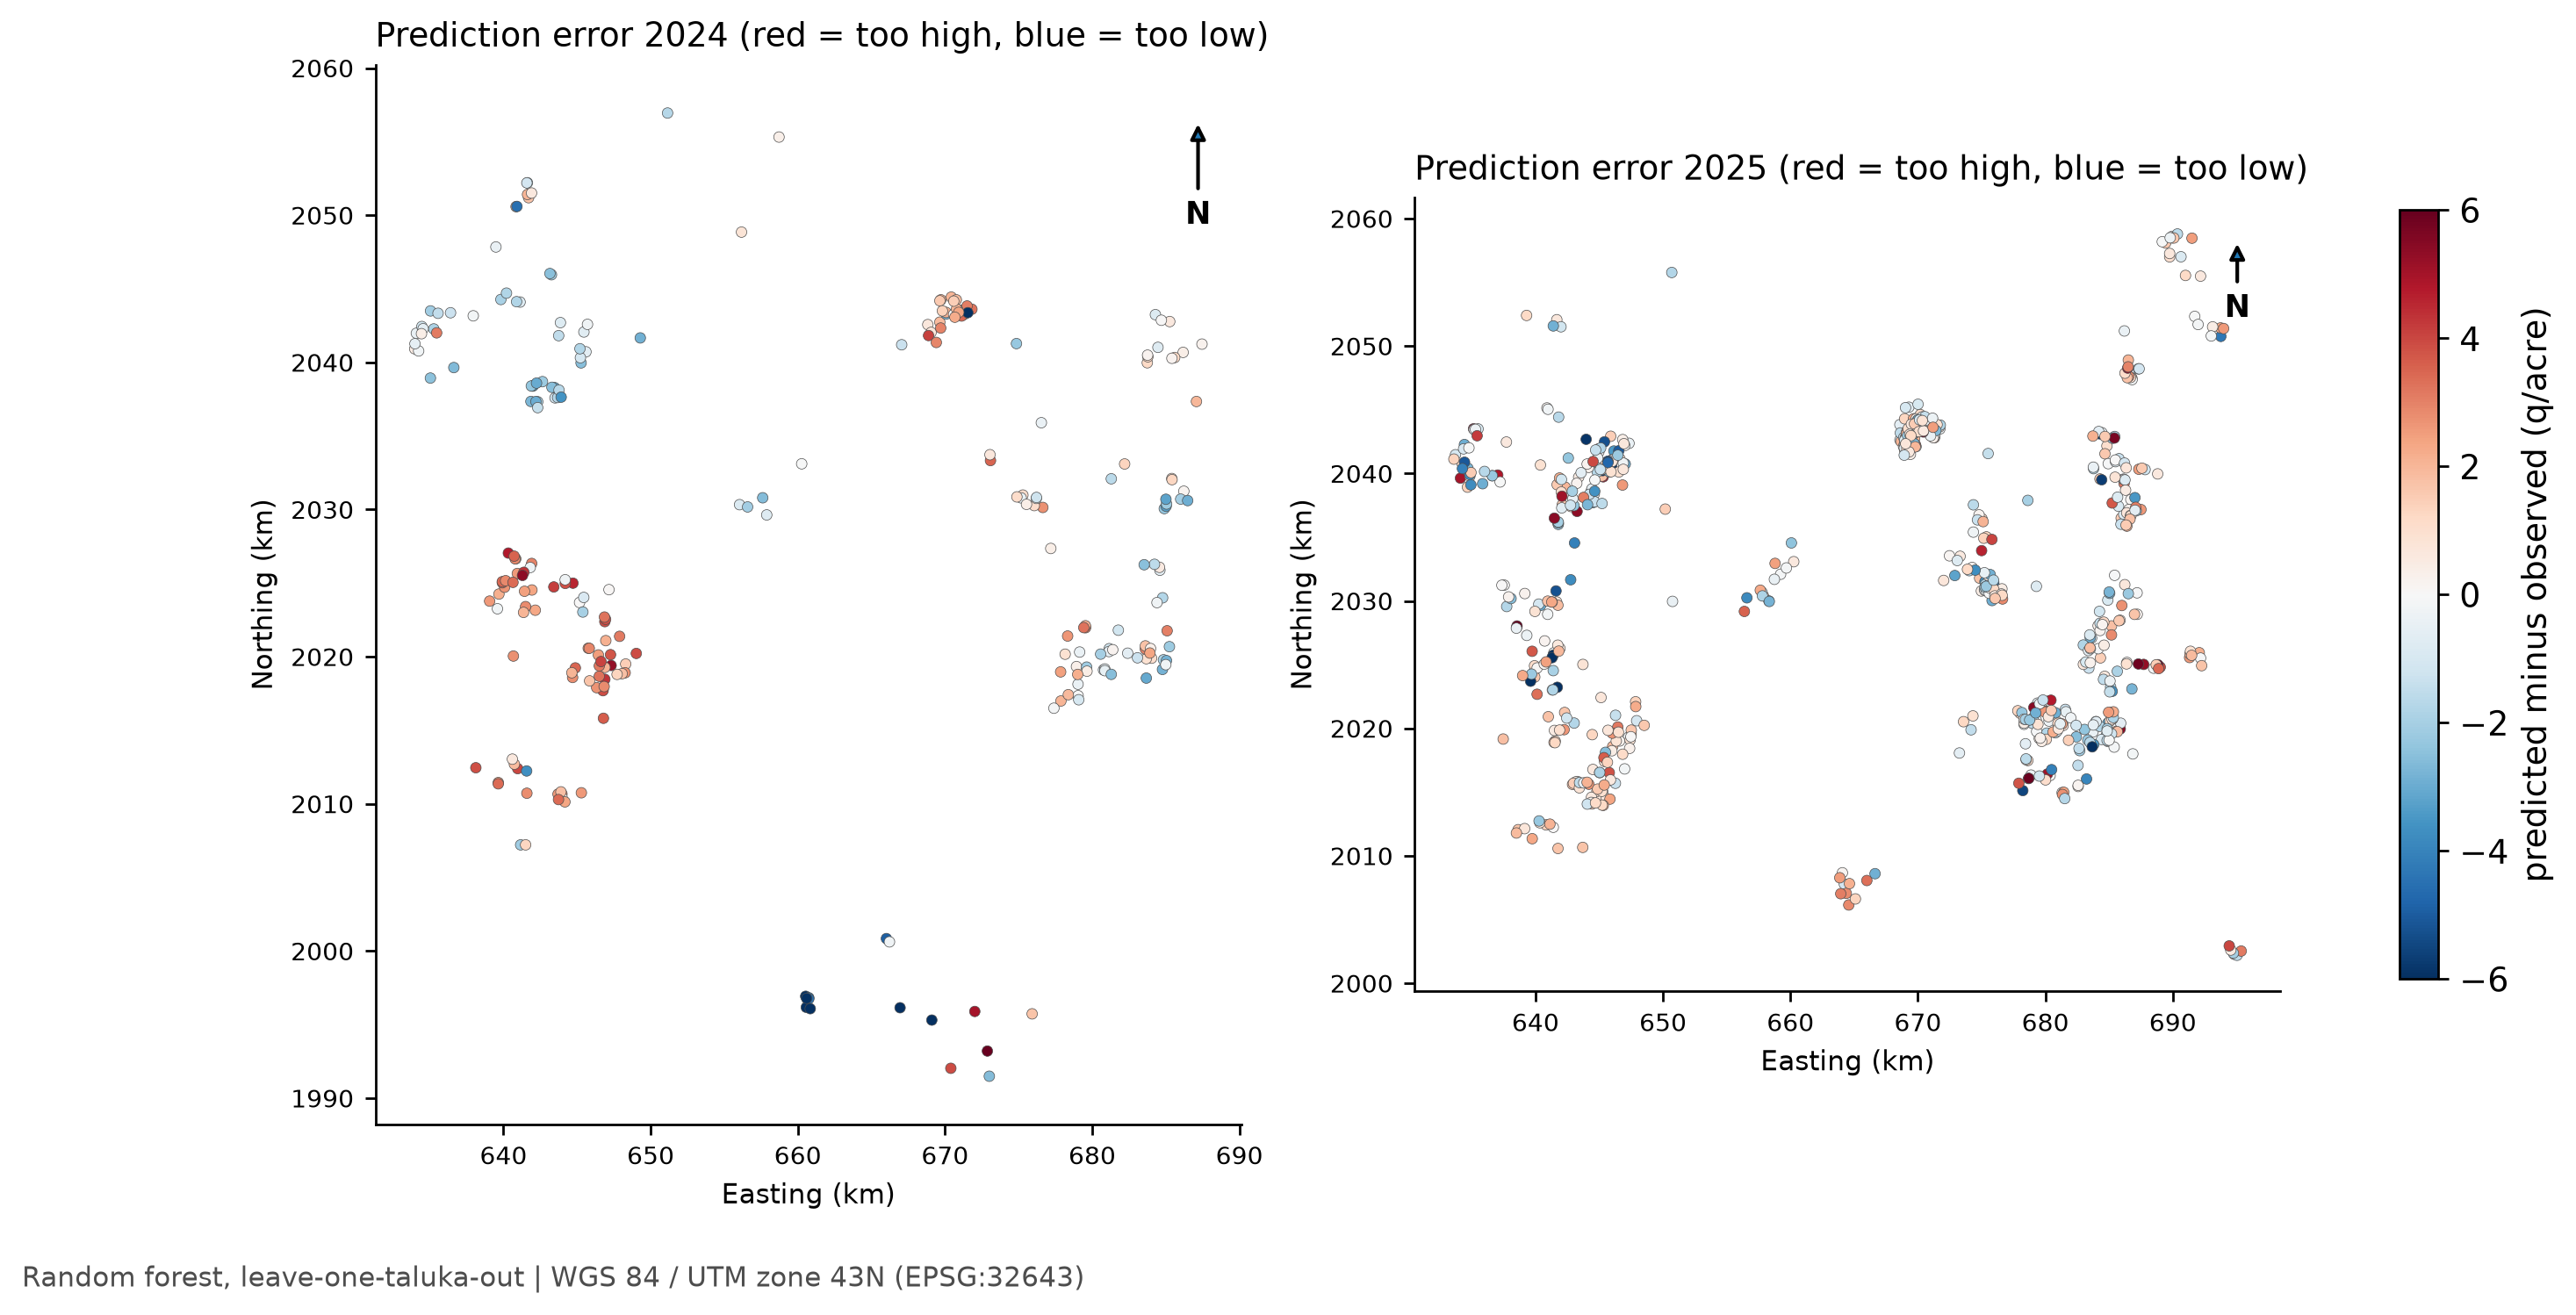

P6_group_tests.png


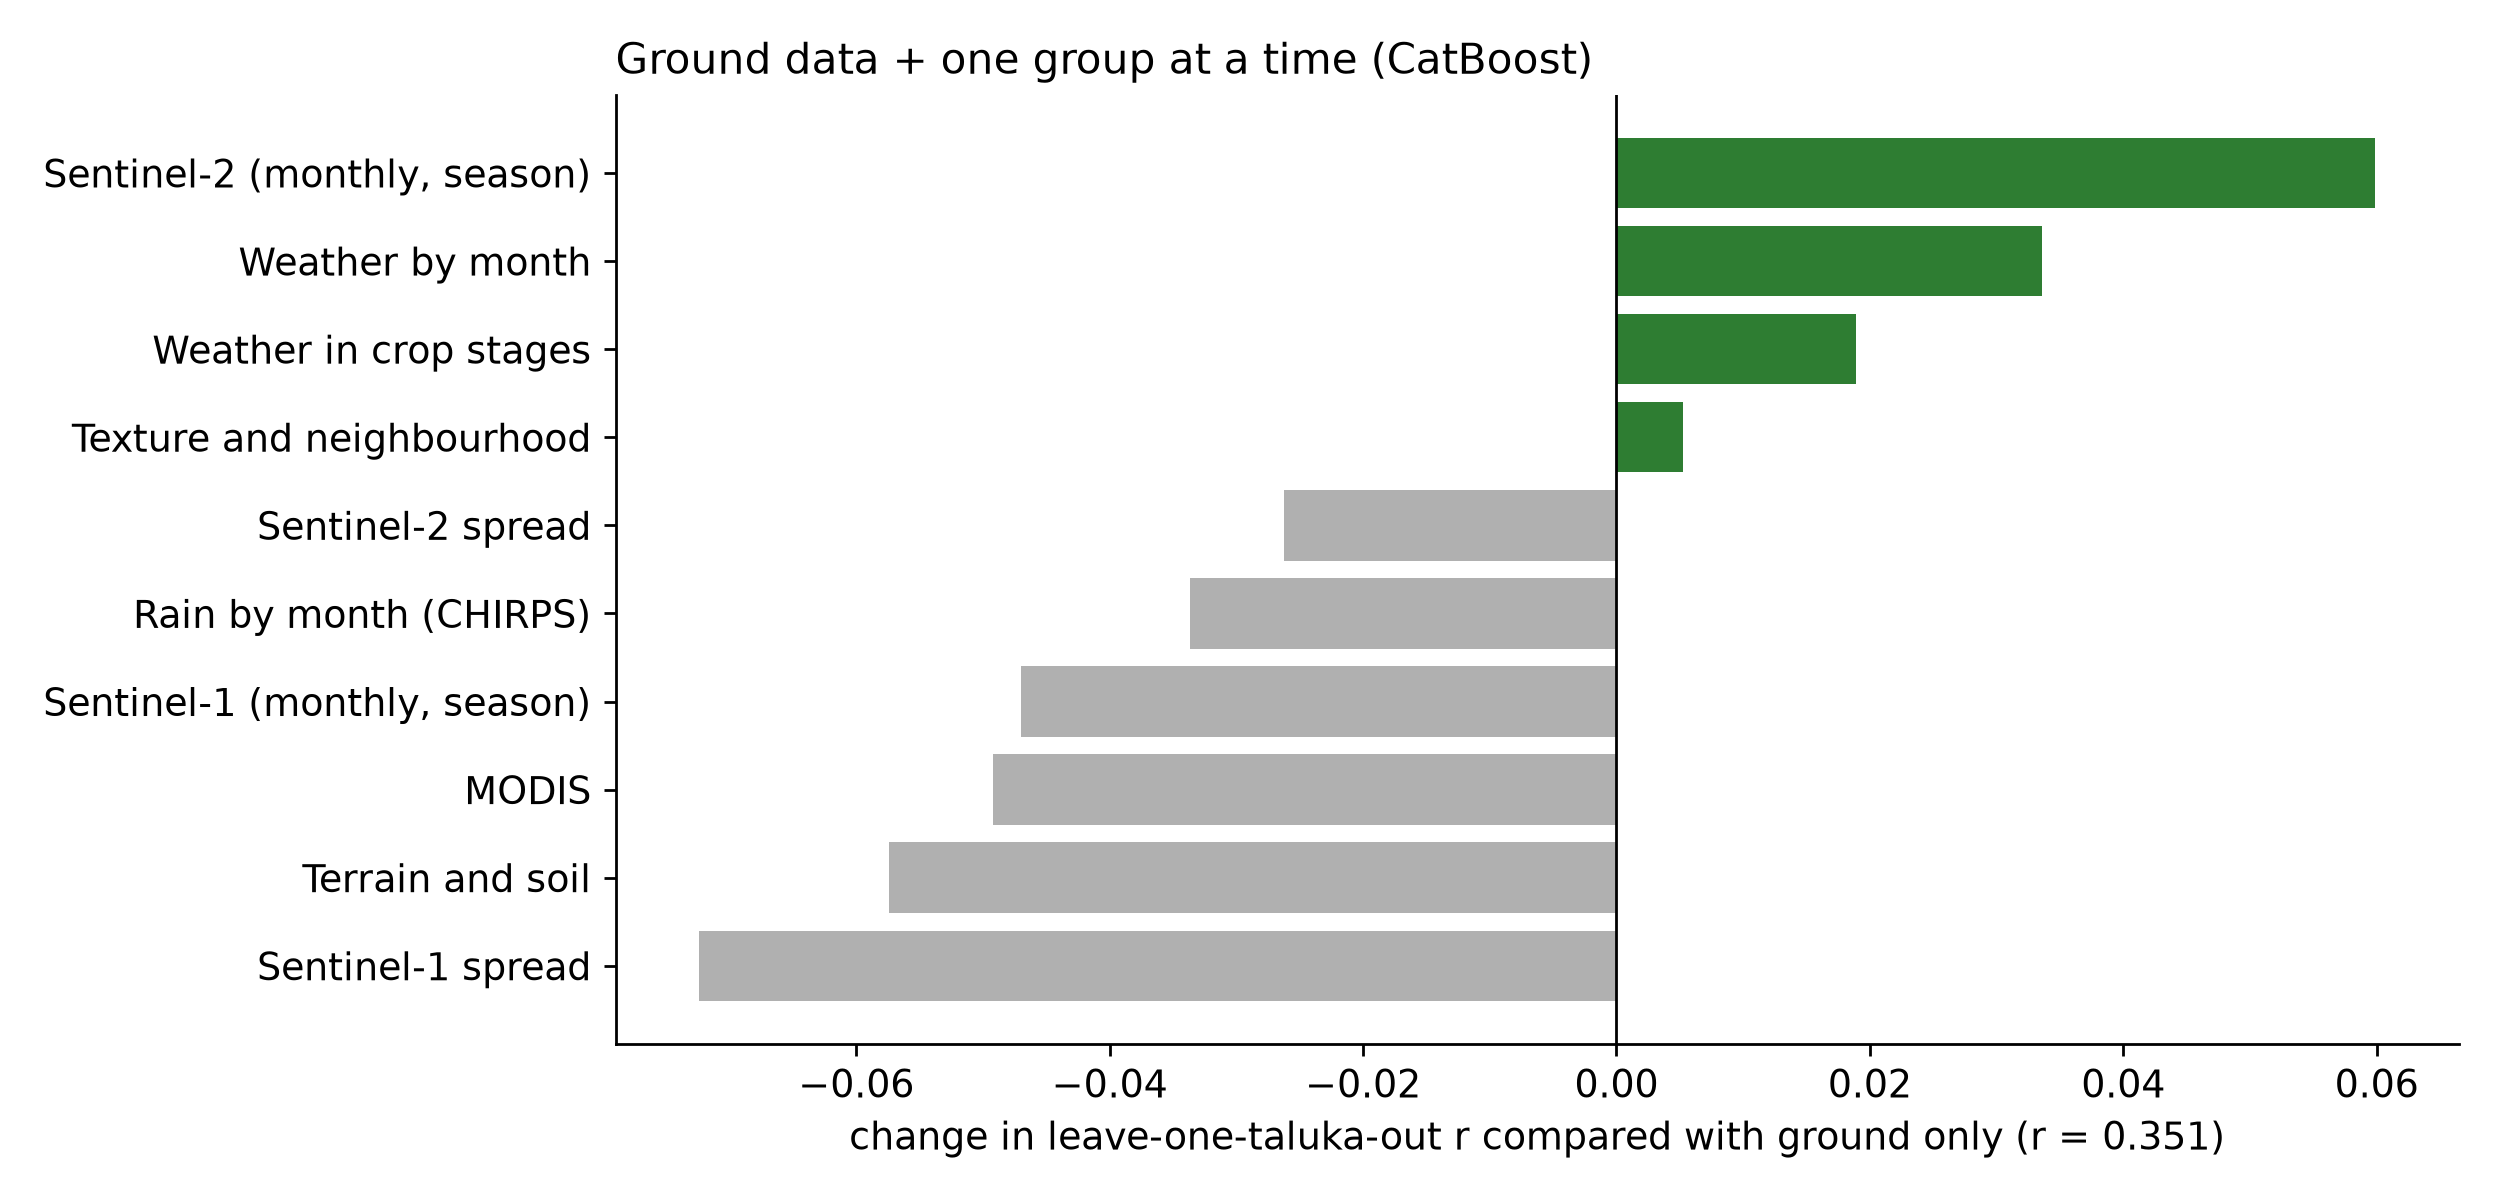

P6_importance_groups.png


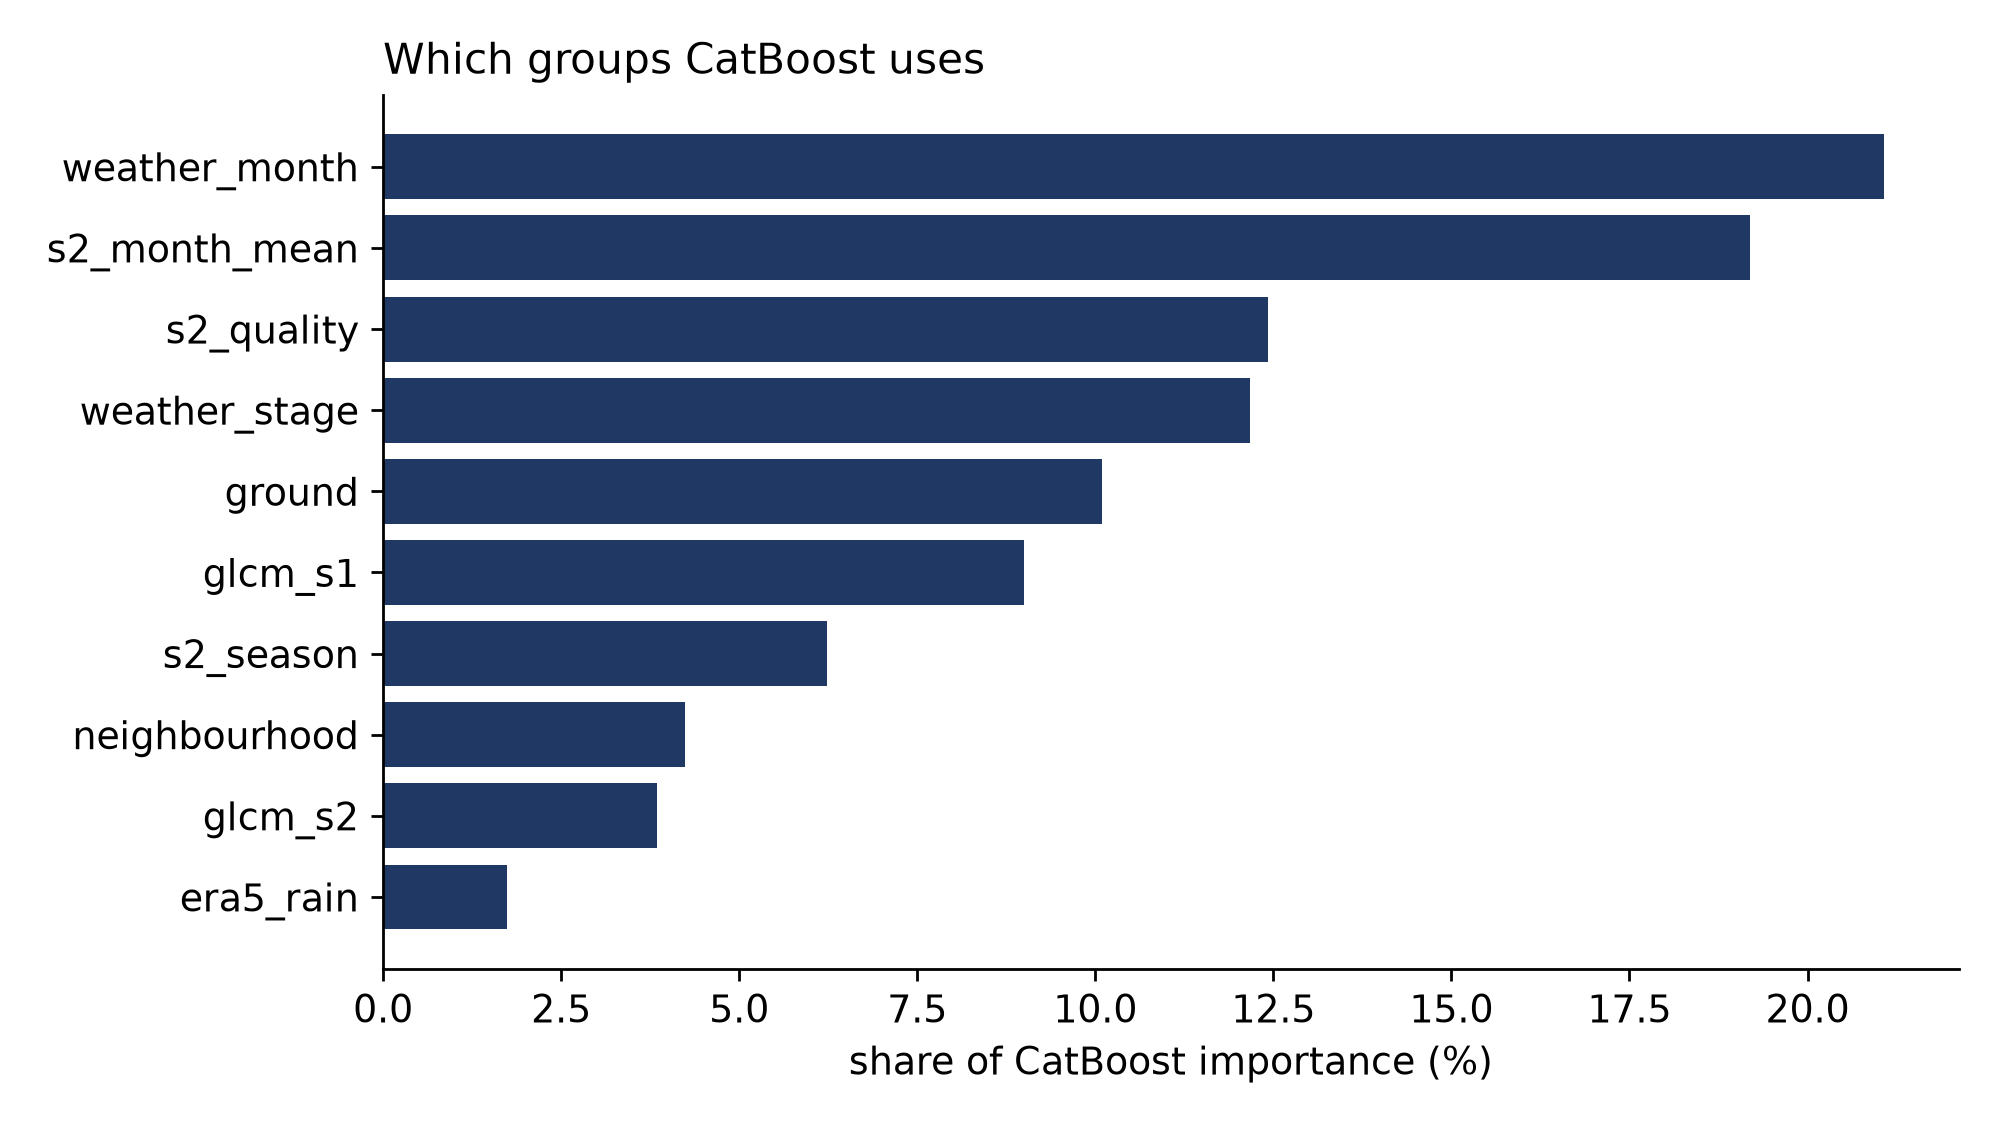

P6_model_families.png


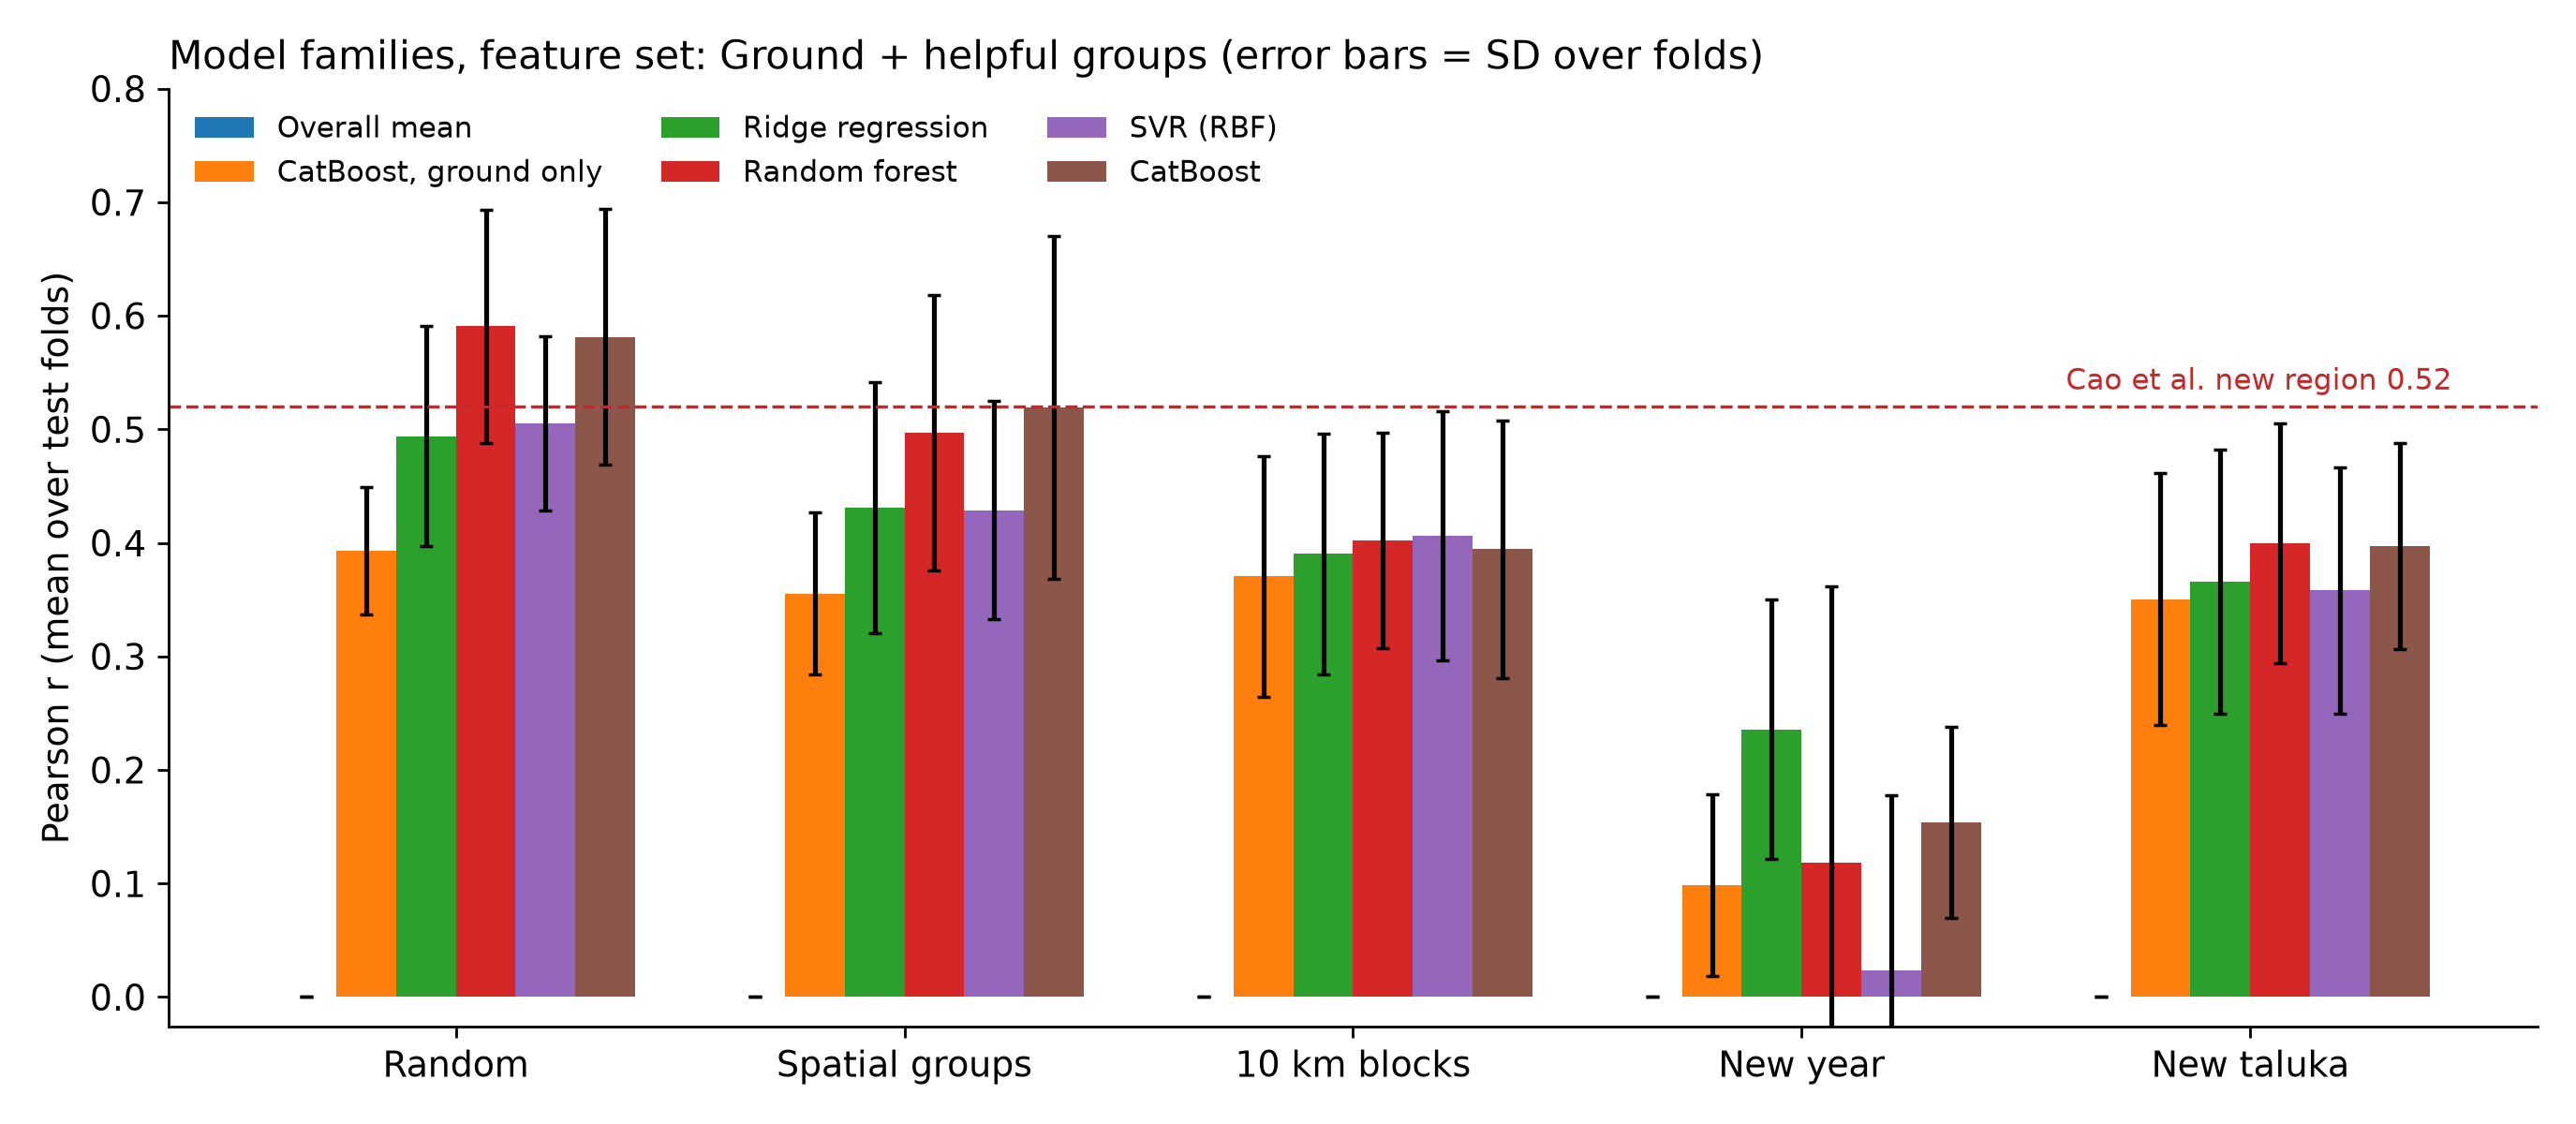

P6_observed_vs_predicted.png


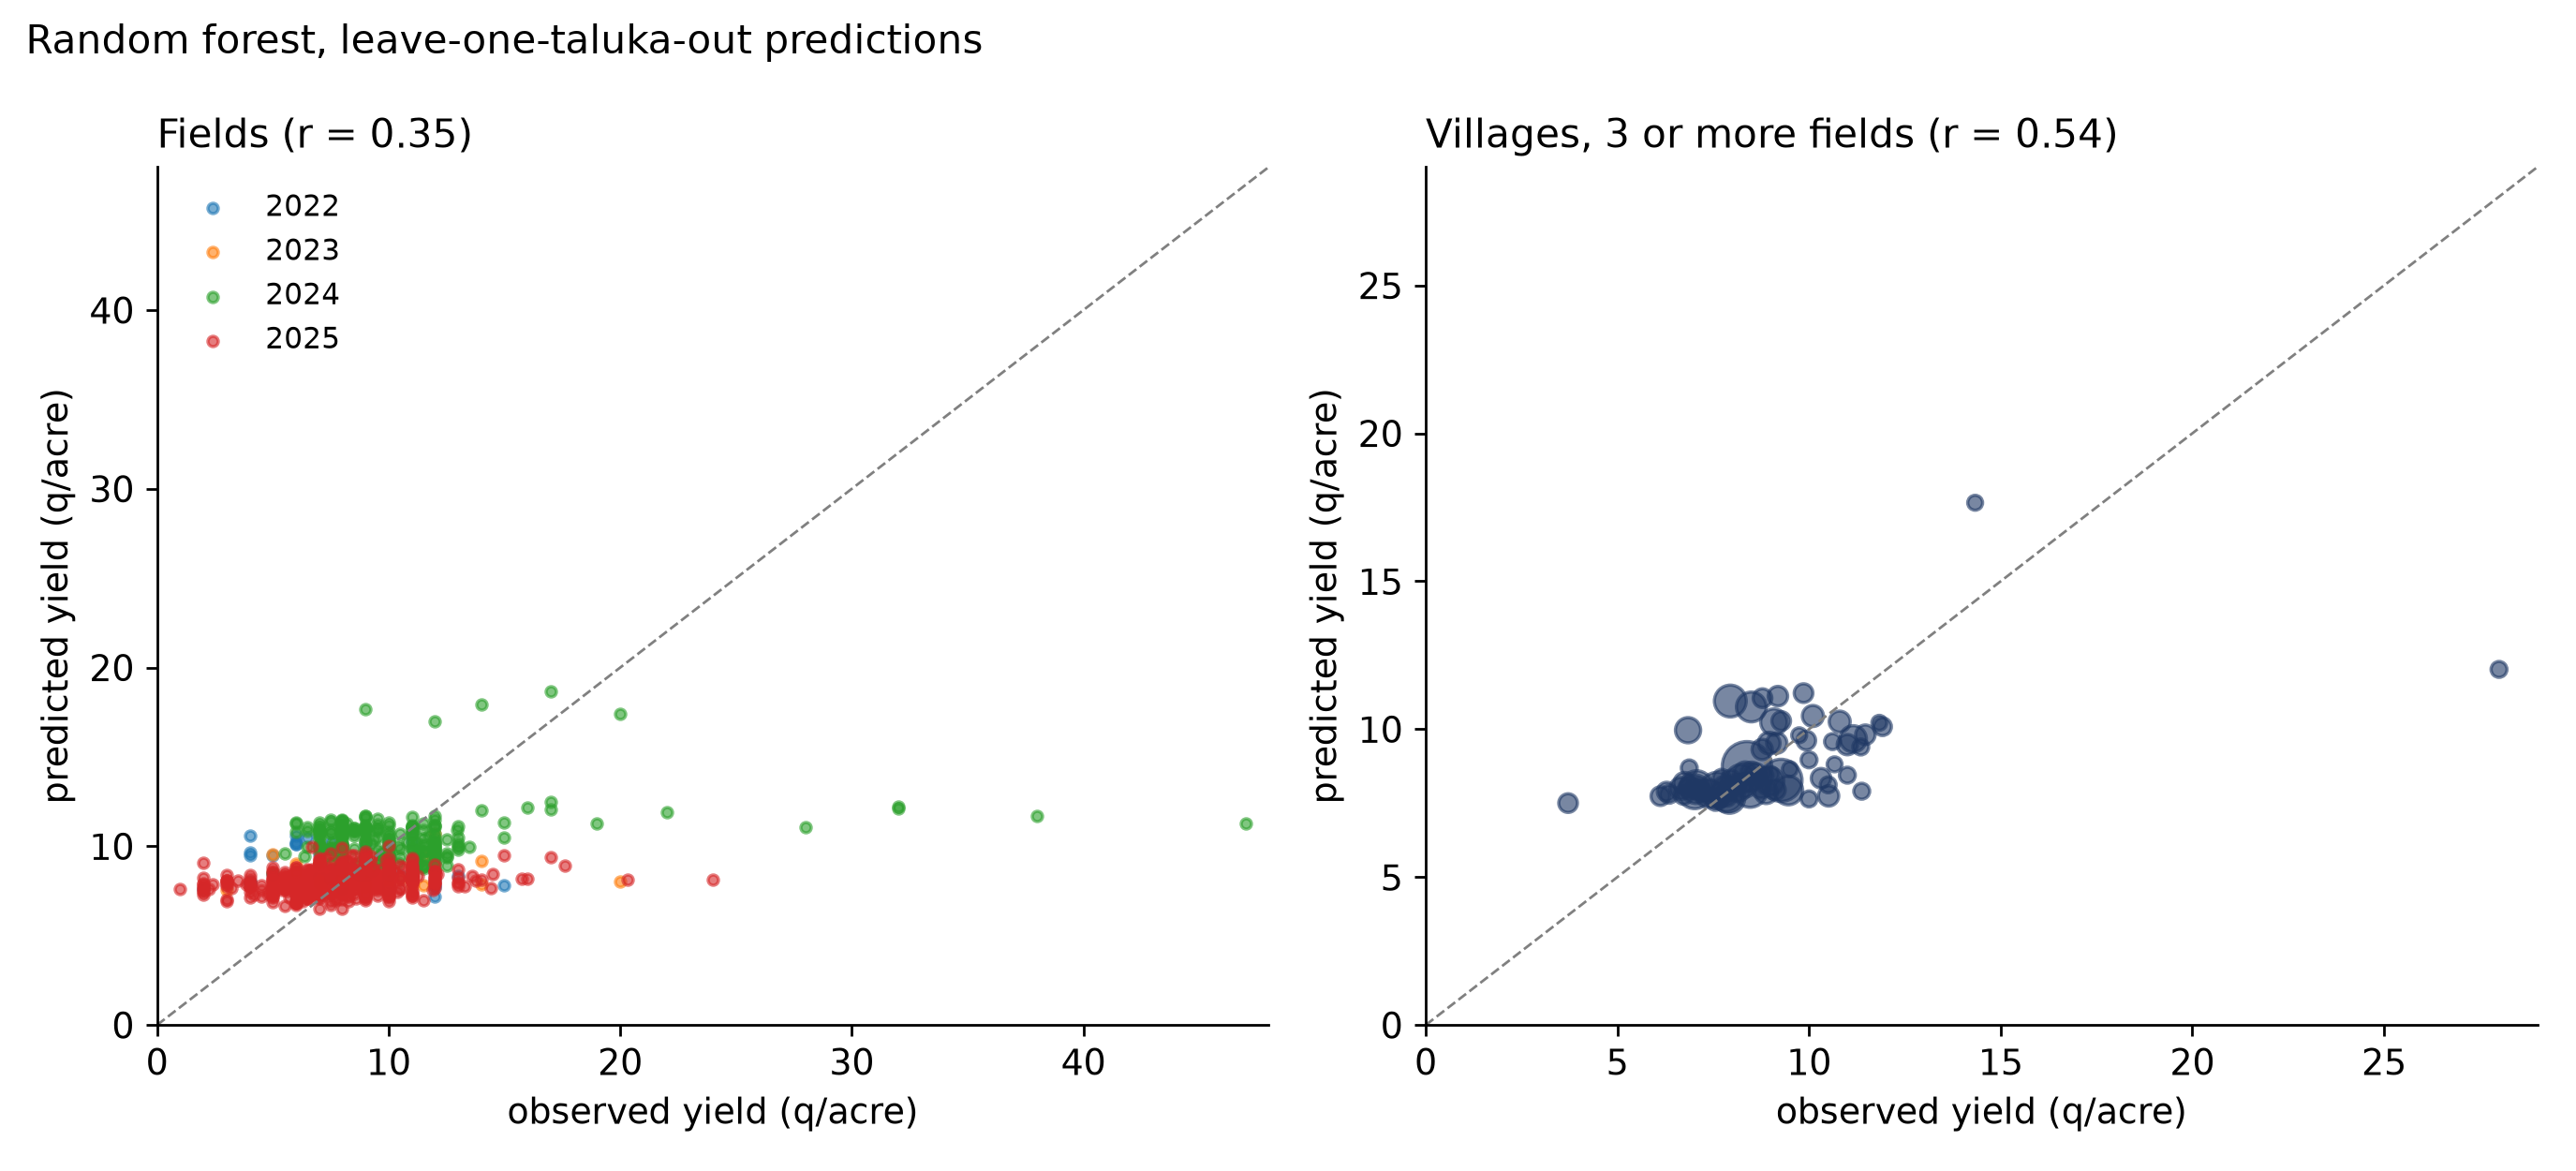

In [1]:
# show the Step 9 figures (made on the HPC and saved as files)
from pathlib import Path
from IPython.display import Image, display
FIG = Path.cwd().parent / "reports" / "figures" / "phase6"
for p in sorted(FIG.glob("P6_*.png")):
    print(p.name); display(Image(filename=str(p), width=900))

## Step 10: Save

All scores, tests and the out-of-fold predictions are saved in `results/phase6/`. No hold-out field is in any of them.

**Found:** 11 result files saved in `results/phase6/`, including the out-of-fold predictions of every model. No hold-out field is in any of them.

In [11]:
# Step 10: save the out-of-fold predictions of every model (hold-out fields are not in them)
pd.concat([oof.assign(model=k) for k, (_, _, oof) in fam.items()]).to_csv(OUT / "P6_oof_predictions.csv", index=False)
pd.Series(SETS[BEST], name="feature").to_csv(OUT / "P6_chosen_features.csv", index=False)
print("saved in results/phase6:", sorted(p.name for p in OUT.glob("P6_*.csv")))

saved in results/phase6: ['P6_chosen_features.csv', 'P6_error_correlogram.csv', 'P6_feature_sets.csv', 'P6_group_tests.csv', 'P6_importance.csv', 'P6_model_scores.csv', 'P6_model_scores_per_fold.csv', 'P6_oof_predictions.csv', 'P6_paired_tests.csv', 'P6_village_level.csv', 'P6_vs_cao.csv']


## Summary

| Question | Answer |
|---|---|
| Which groups help? | Sentinel-2 (clearest), monthly weather, crop-stage weather, texture; Sentinel-1, spread, rain, terrain, soil and MODIS do not help on their own |
| Best feature set | ground + helpful groups, 128 features (all 331 is worse) |
| Best model | random forest (CatBoost almost equal) |
| New taluka r | 0.40 (ground only 0.35; corrected t-test p = 0.015); target 0.52 |
| Village level r | 0.54 |
| New year r | 0.12; not predictable with 4 seasons |
| Warnings | the 1 km grouping is now too small (errors alike up to about 3 km); top features include place and time markers (coarse weather, cloud counts) |

**Next (Phase 6b):** grouping distance raised to about 3 km; loss functions (MAE, Huber); feature selection nested inside each fold; a test without the place and time markers.